In [ ]:
!pip install openeo
!pip install xarray
!pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 357.8/357.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 5.3 MB/s eta 0:00:00


In [ ]:
import openeo
import xarray
import matplotlib.pyplot as plt
import json
from openeo.api.process import Parameter
import rasterio
import numpy as np

In [ ]:
connection = openeo.connect("openeo.dataspace.copernicus.eu")
connection.authenticate_oidc()

Visit https://identity.dataspace.copernicus.eu/auth/realms/CDSE/device?user_code=LRSN-SGKS 📋 to authenticate.

✅ Authorized successfully

Authenticated using device code flow.


<Connection to 'https://openeo.dataspace.copernicus.eu/openeo/1.2/' with OidcBearerAuth>

#2024_baja intensidad

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2024-02-20", "2024-04-30"),
    spatial_extent={
        "west": -98.054004,
        "south": 19.274712,
        "east": -98.048843,
        "north": 19.280972,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)


In [ ]:
s2_cube.download("SanCristobal.nc")

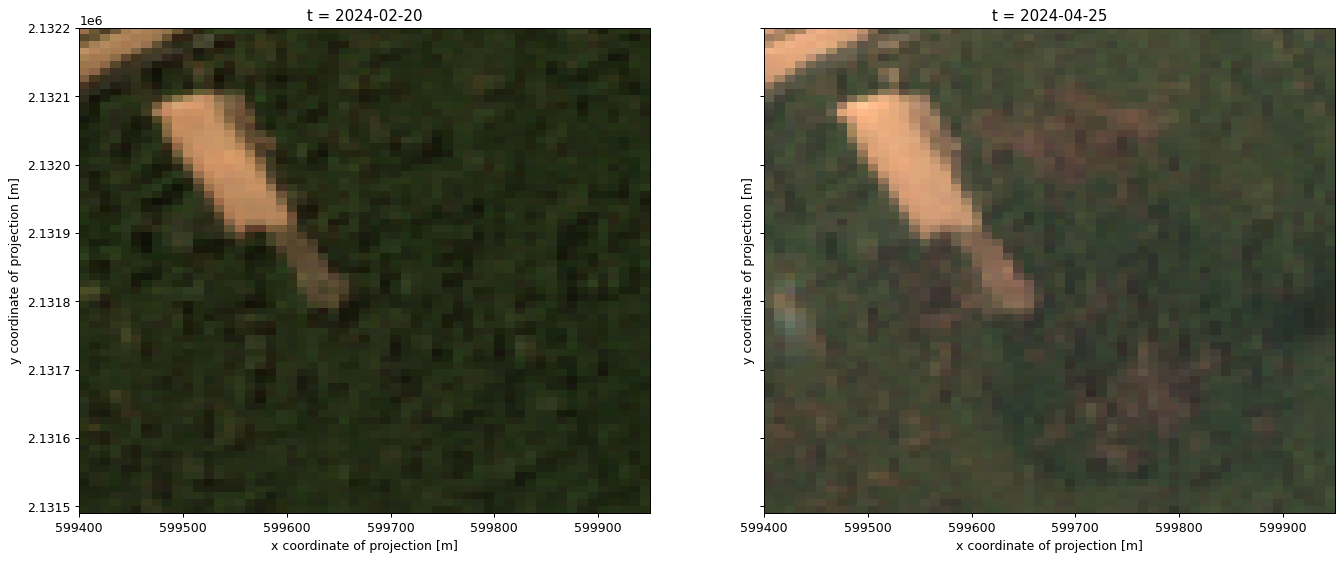

In [ ]:
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

In [ ]:
band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

In [ ]:
nir = cube.band("B08")
swir = cube.band("B12")

nbr = (nir - swir) / (swir + nir)
nbr

In [ ]:
nbr = nbr.max_time()

In [ ]:
connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

In [ ]:
postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2024-04-24", "2024-04-26"],
    bbox={
        "west": -98.054004,
        "south": 19.274712,
        "east": -98.048843,
        "north": 19.280972,}
)

In [ ]:
postbr2016.download("postnbr2016.tiff")

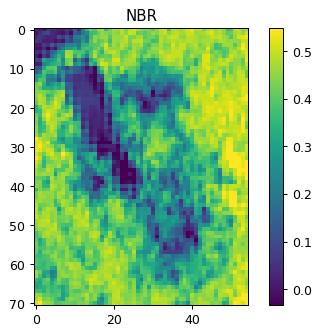

In [ ]:
data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)

In [ ]:
prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2024-02-20", "2024-02-22"],
    bbox={
        "west": -98.054004,
        "south": 19.274712,
        "east": -98.048843,
        "north": 19.280972,}
)

In [ ]:
prenbr2016.download("prenbr2016.tiff")

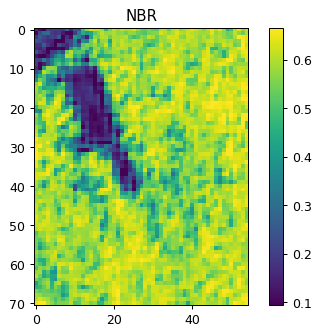

In [ ]:
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)

In [ ]:
pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

In [ ]:
dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

In [ ]:
meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/dnbr.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

In [ ]:
img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

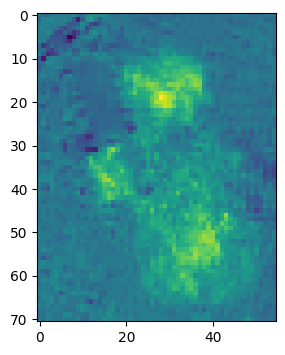

<Axes: >

In [ ]:
from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

In [ ]:
scl = scl_image.read()
scl = np.array(scl)
scl

array([[[0.14727795, 0.09916028, 0.08720868, ..., 0.14312285,
         0.12463784, 0.13120168],
        [0.10246091, 0.17940877, 0.2034394 , ..., 0.08133039,
         0.0880568 , 0.09778816],
        [0.14169863, 0.18528509, 0.17262003, ..., 0.15871513,
         0.13656217, 0.10526776],
        ...,
        [0.13690564, 0.12489989, 0.14660853, ..., 0.09403223,
         0.1071806 , 0.11047316],
        [0.12893927, 0.1226145 , 0.18015563, ..., 0.09058505,
         0.10746753, 0.10454184],
        [0.13227624, 0.11921096, 0.2007336 , ..., 0.11628234,
         0.13626075, 0.1031664 ]]], dtype=float32)

In [ ]:
#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)

In [ ]:
meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

In [ ]:
water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

In [ ]:
img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

In [ ]:
water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

In [ ]:
from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

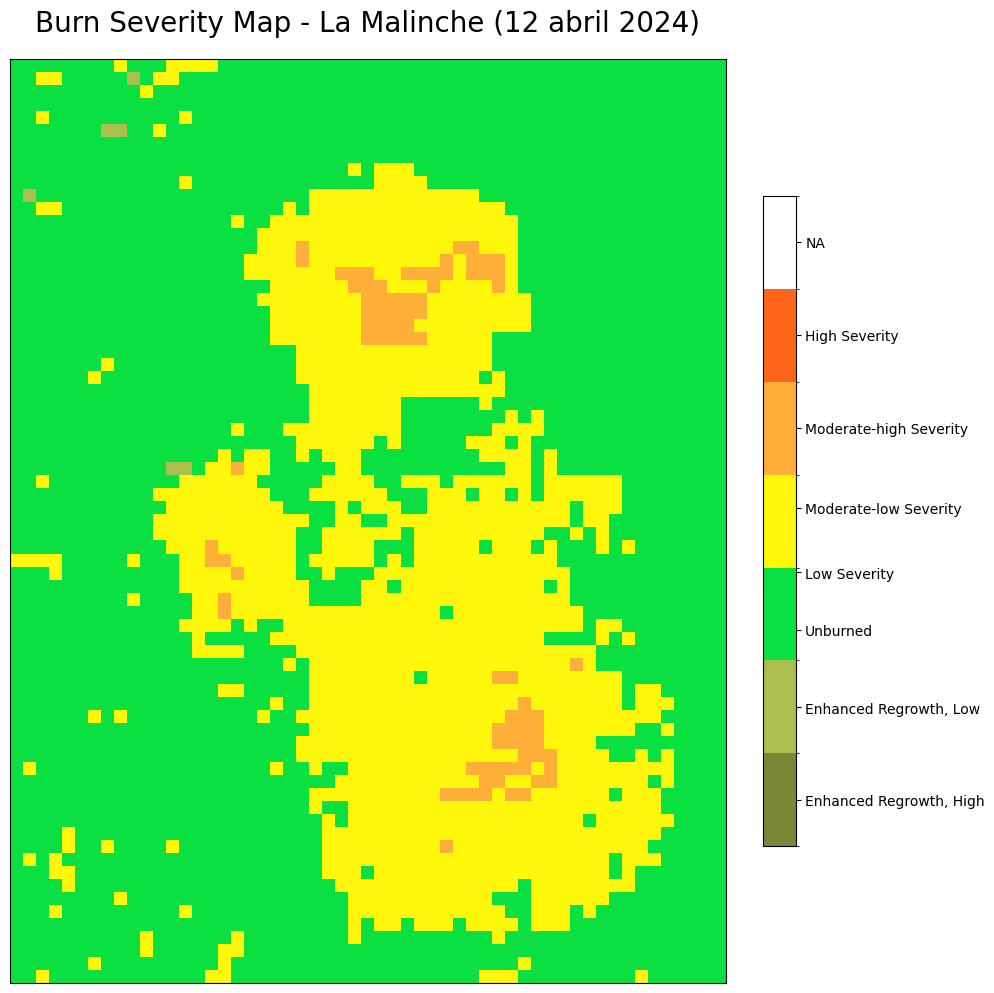

In [ ]:
# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2024

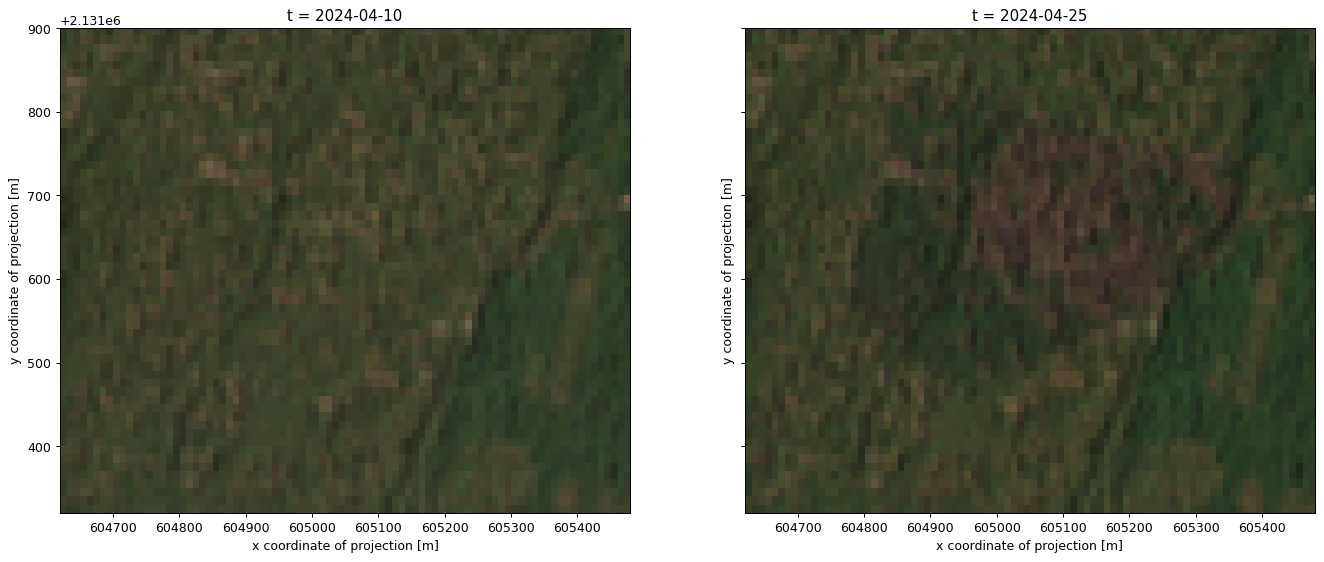

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2024-04-10", "2024-04-30"),
    spatial_extent={
        "west": -98.0043114,
        "south": 19.2729154,
        "east": -97.9962229,
        "north": 19.2780474,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

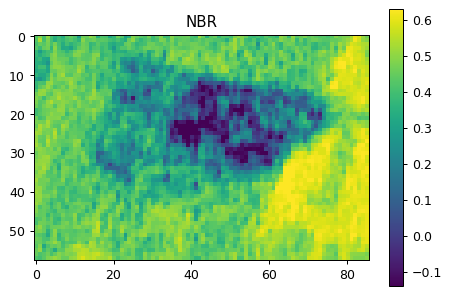

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2024-04-24", "2024-04-26"],
    bbox={
"west": -98.0043114,
        "south": 19.2729154,
        "east": -97.9962229,
        "north": 19.2780474,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)

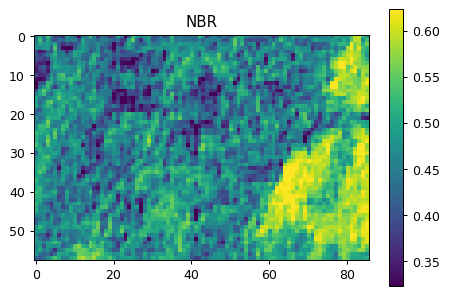

In [ ]:
prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2024-04-09", "2024-04-11"],
    bbox={
        "west": -98.0043114,
        "south": 19.2729154,
        "east": -97.9962229,
        "north": 19.2780474,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)

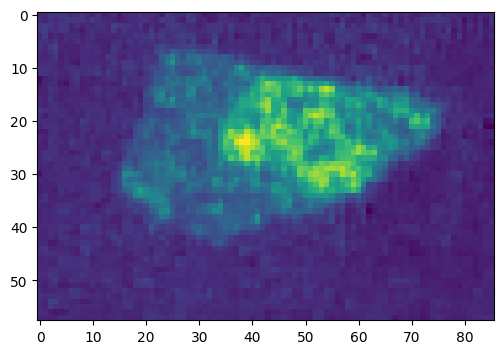

<Axes: >

In [ ]:
pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/dnbr.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)


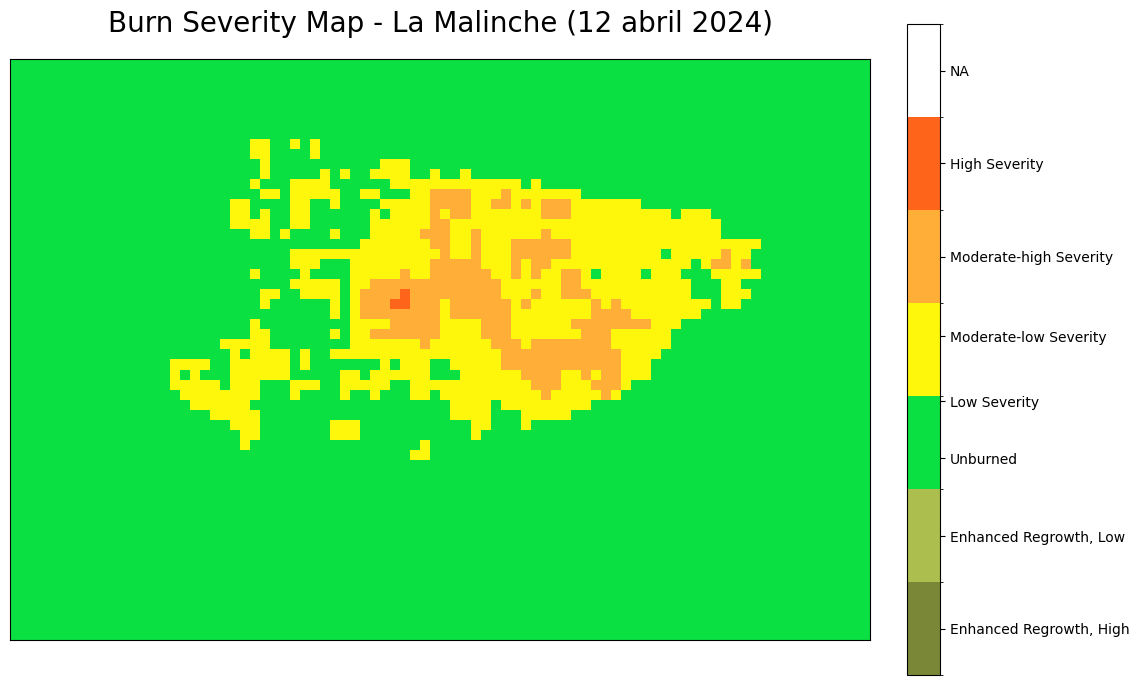

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2019


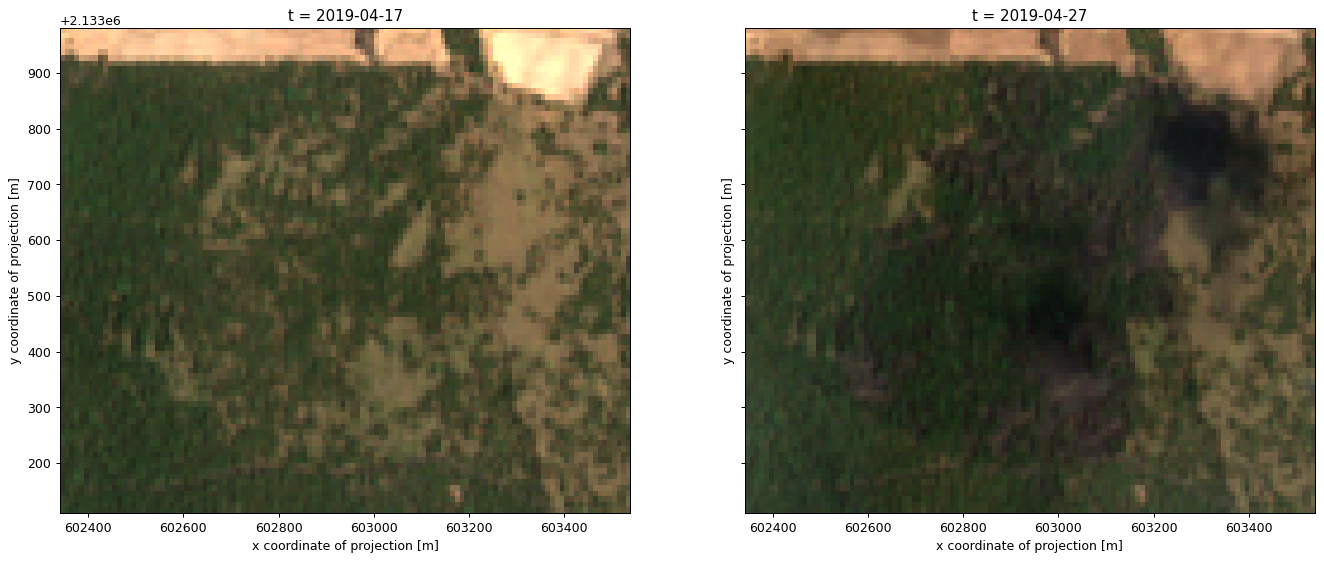

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2019-04-15", "2019-05-01"),
    spatial_extent={
        "west": -98.025942,
        "south": 19.289171,
        "east": -98.014615,
        "north": 19.296940,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

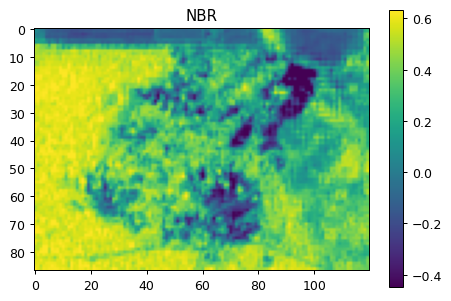

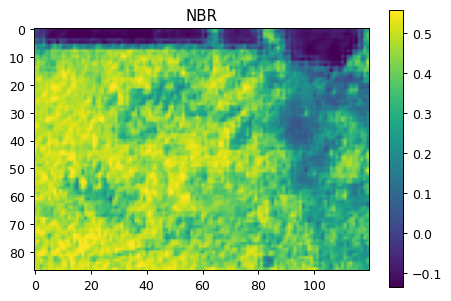

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2019-04-26", "2019-04-28"],
    bbox={
"west": -98.025942,
        "south": 19.289171,
        "east": -98.014615,
        "north": 19.296940,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2024-04-09", "2024-04-11"],
    bbox={
        "west": -98.025942,
        "south": 19.289171,
        "east": -98.014615,
        "north": 19.296940,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


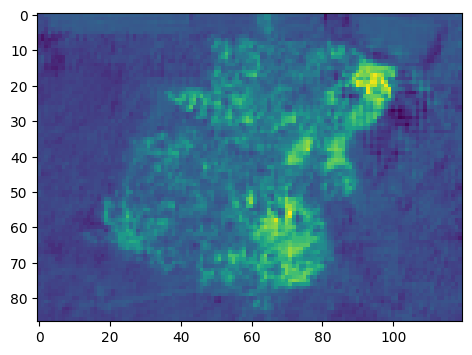

<Axes: >

In [ ]:
pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2019_1.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

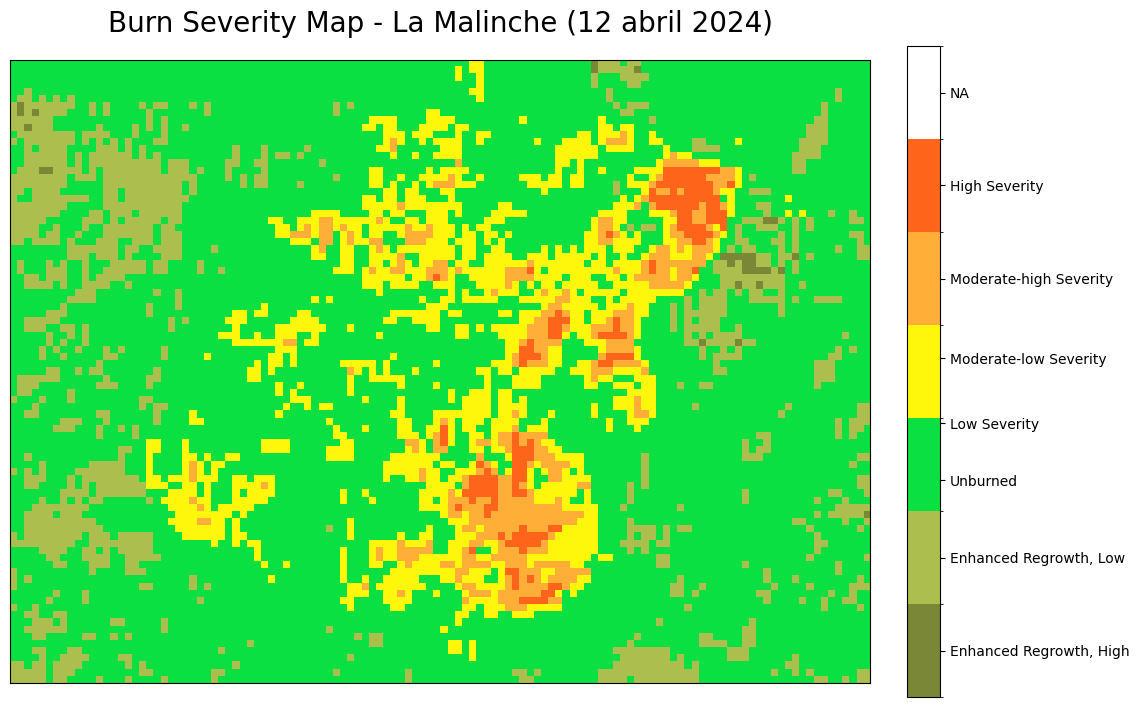

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2021



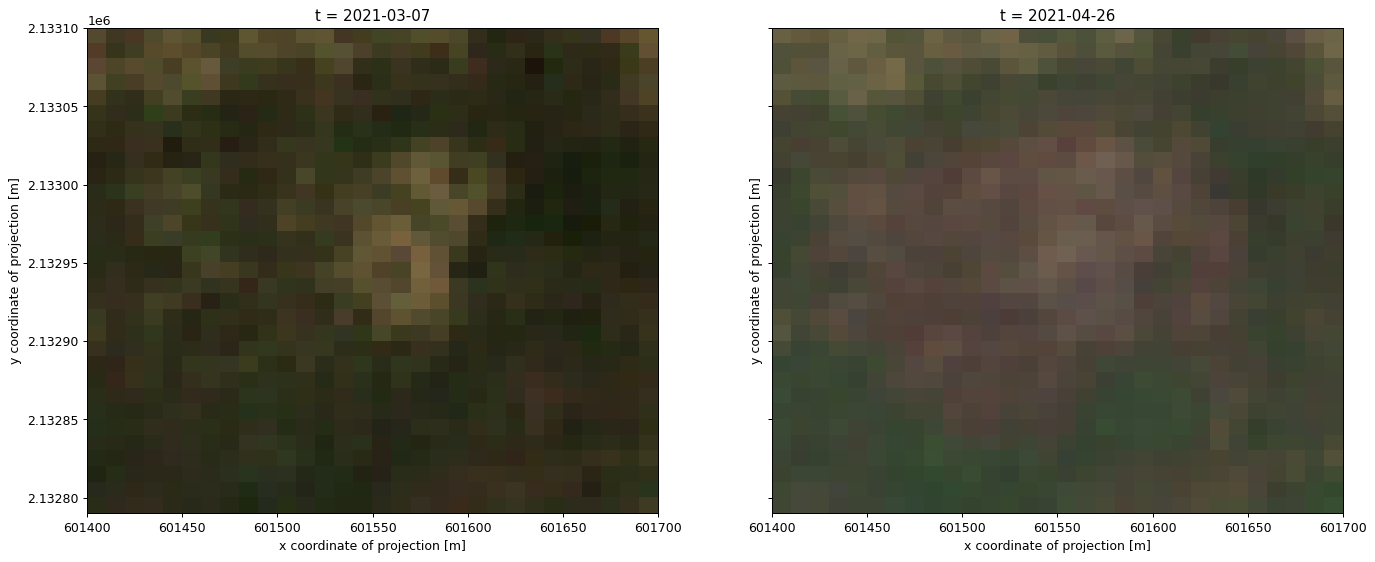

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2021-03-03", "2021-05-01"),
    spatial_extent={
        "west": -98.034884,
        "south": 19.286329,
        "east": -98.032109,
        "north": 19.289093,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

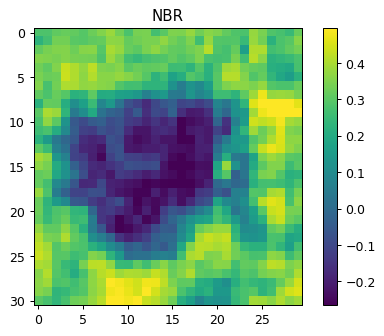

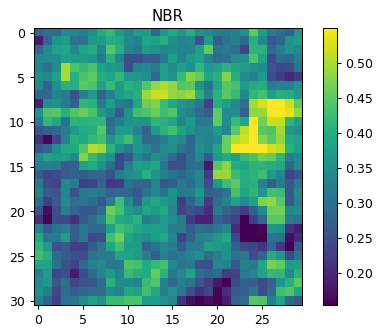

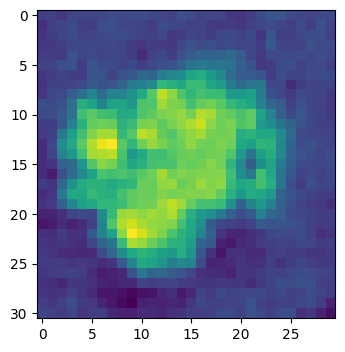

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2021-03-26", "2021-03-28"],
    bbox={
"west": -98.034884,
        "south": 19.286329,
        "east": -98.032109,
        "north": 19.289093,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2021-03-06", "2021-03-08"],
    bbox={
        "west": -98.034884,
        "south": 19.286329,
        "east": -98.032109,
        "north": 19.289093,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/dnbr.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

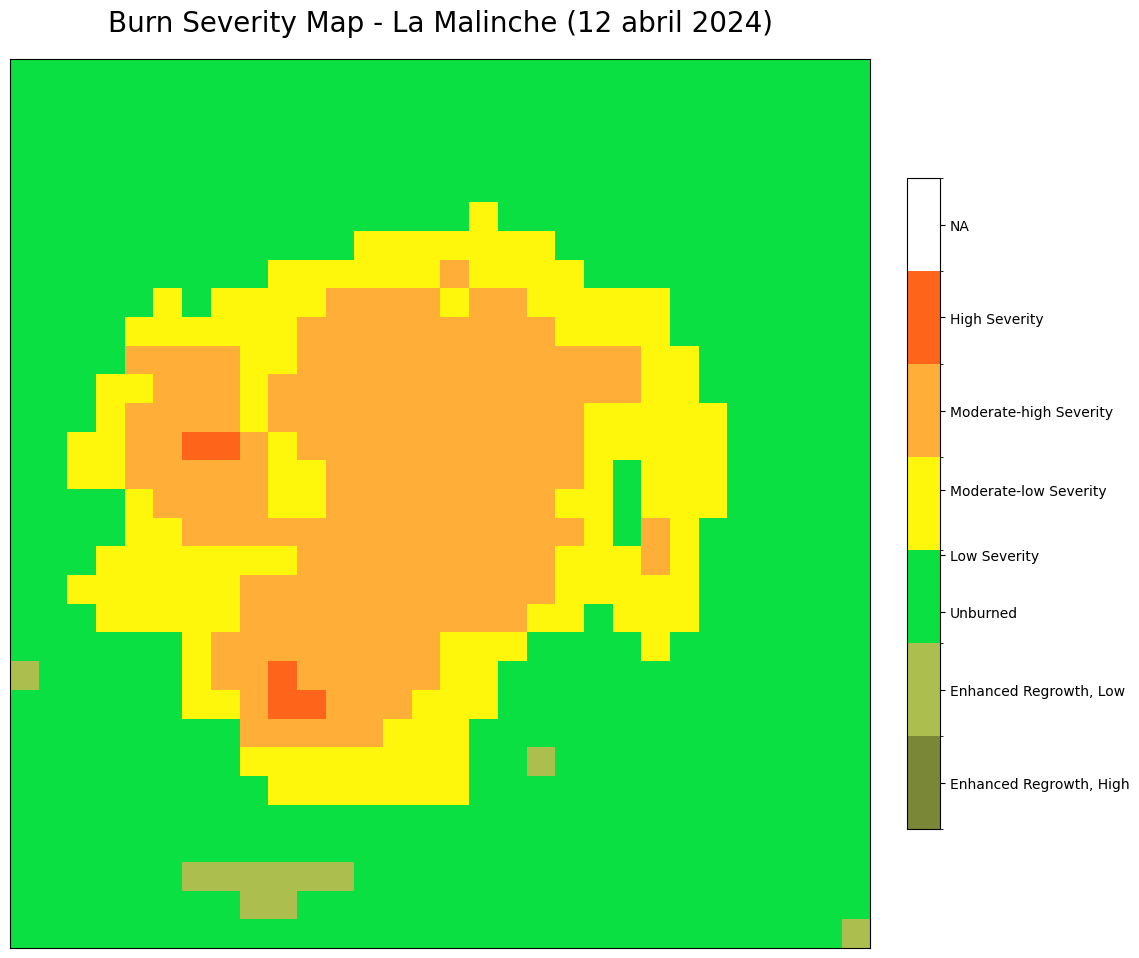

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2019_2



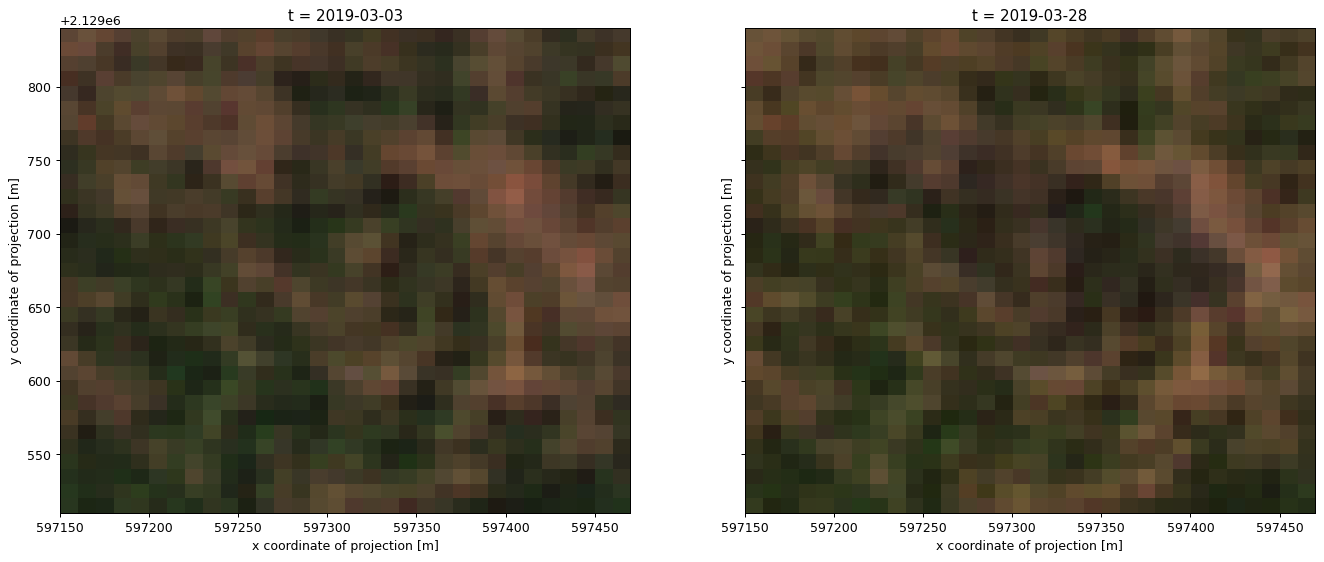

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2019-03-01", "2019-03-30"),
    spatial_extent={
        "west": -98.075465,
        "south": 19.256969,
        "east": -98.072597,
        "north": 19.259765,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

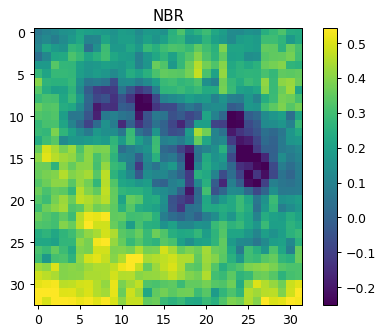

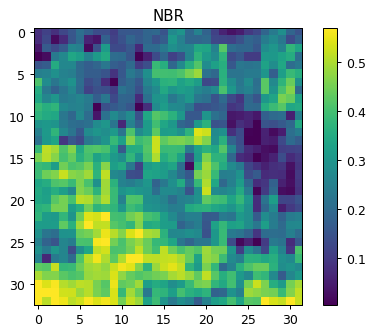

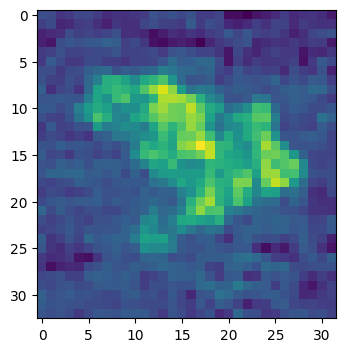

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2019-03-27", "2019-03-29"],
    bbox={
"west": -98.075465,
        "south": 19.256969,
        "east": -98.072597,
        "north": 19.259765,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2019-03-02", "2019-03-04"],
    bbox={
        "west": -98.075465,
        "south": 19.256969,
        "east": -98.072597,
        "north": 19.259765,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2019_2.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

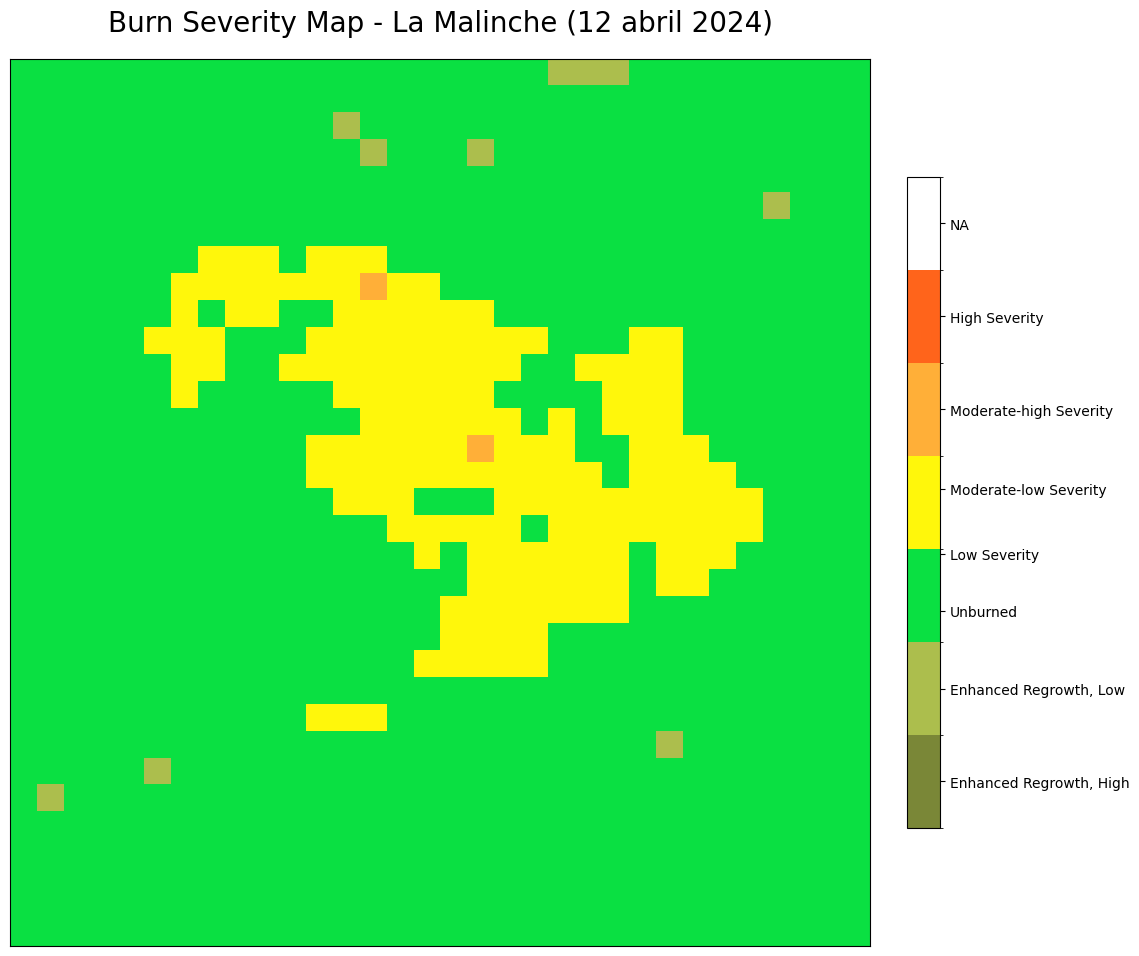

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2019_3



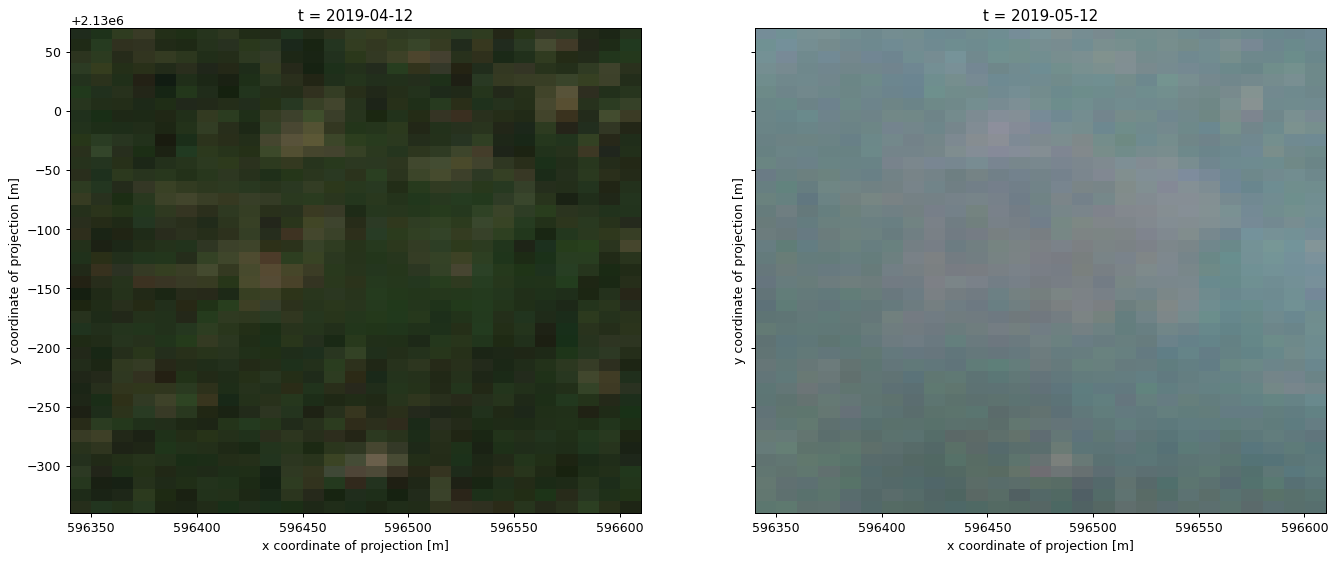

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2019-04-01", "2019-05-20"),
    spatial_extent={
        "west": -98.083155,
        "south": 19.258281,
        "east": -98.080762,
        "north": 19.261943,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

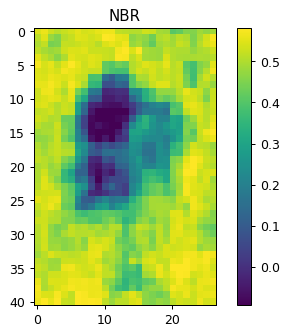

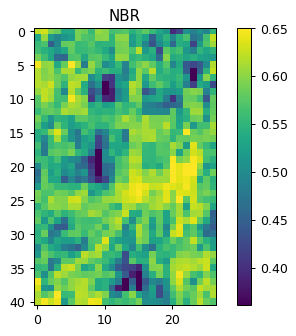

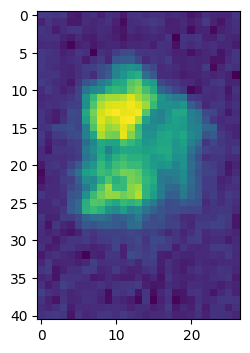

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2019-05-11", "2019-05-13"],
    bbox={
"west": -98.083155,
        "south": 19.258281,
        "east": -98.080762,
        "north": 19.261943,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2019-04-11", "2019-04-13"],
    bbox={
        "west": -98.083155,
        "south": 19.258281,
        "east": -98.080762,
        "north": 19.261943,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2019_3.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

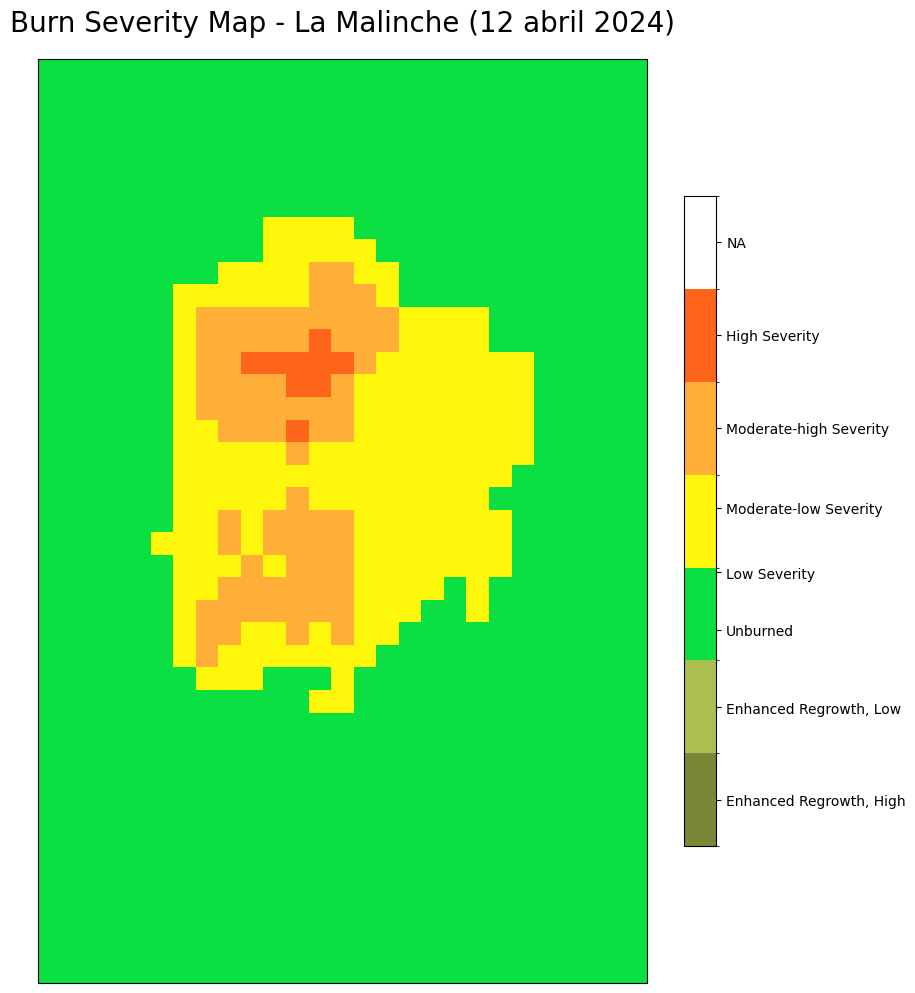

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2025_1



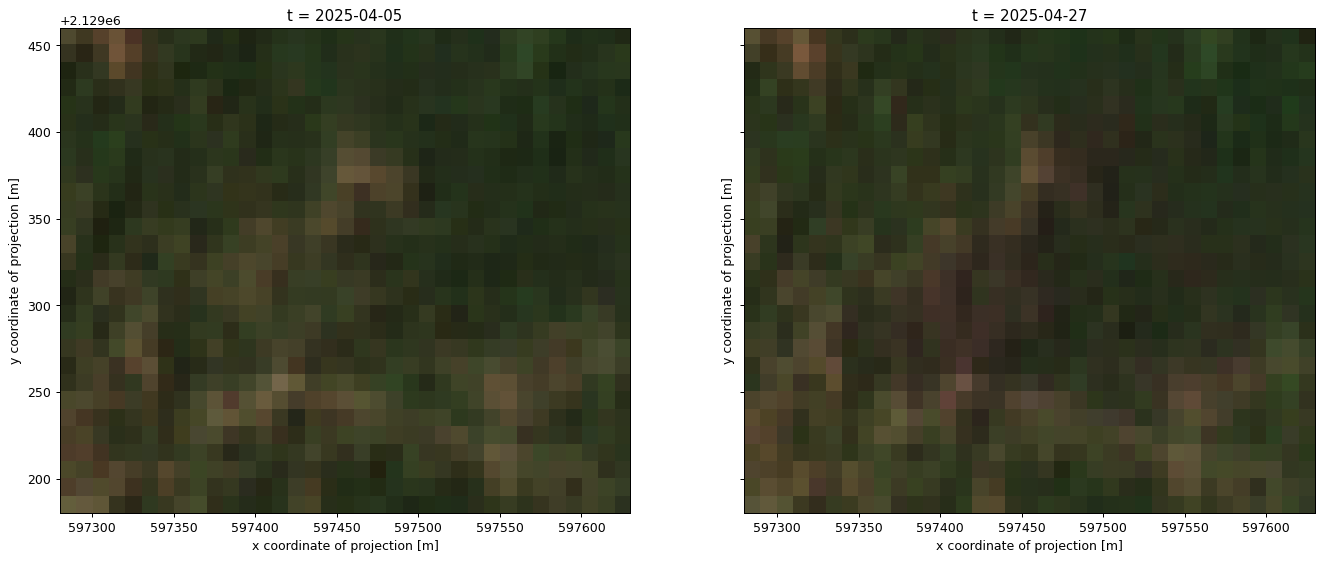

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2025-04-01", "2025-04-30"),
    spatial_extent={
        "west": -98.074266,
        "south": 19.253896,
        "east": -98.071060,
        "north": 19.256401,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

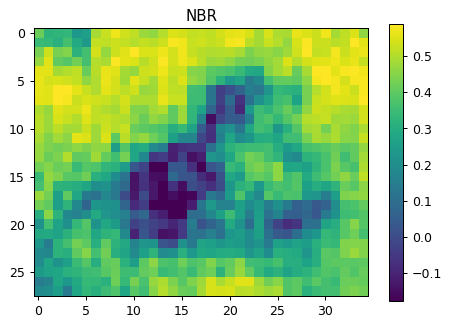

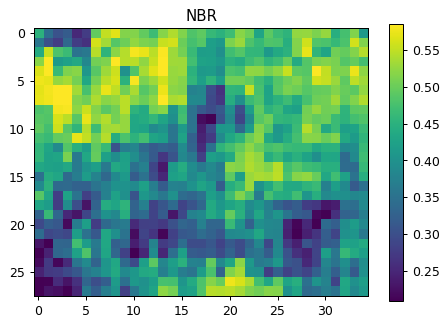

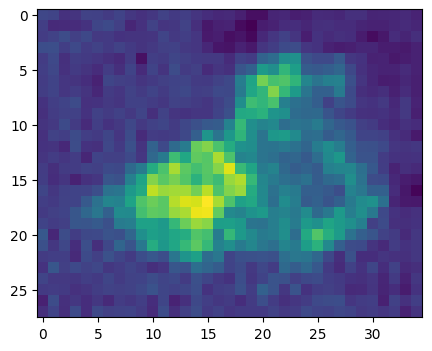

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2025-04-26", "2025-04-28"],
    bbox={
"west": -98.074266,
        "south": 19.253896,
        "east": -98.071060,
        "north": 19.256401,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2025-04-04", "2025-04-06"],
    bbox={
        "west": -98.074266,
        "south": 19.253896,
        "east": -98.071060,
        "north": 19.256401,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2025_1.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

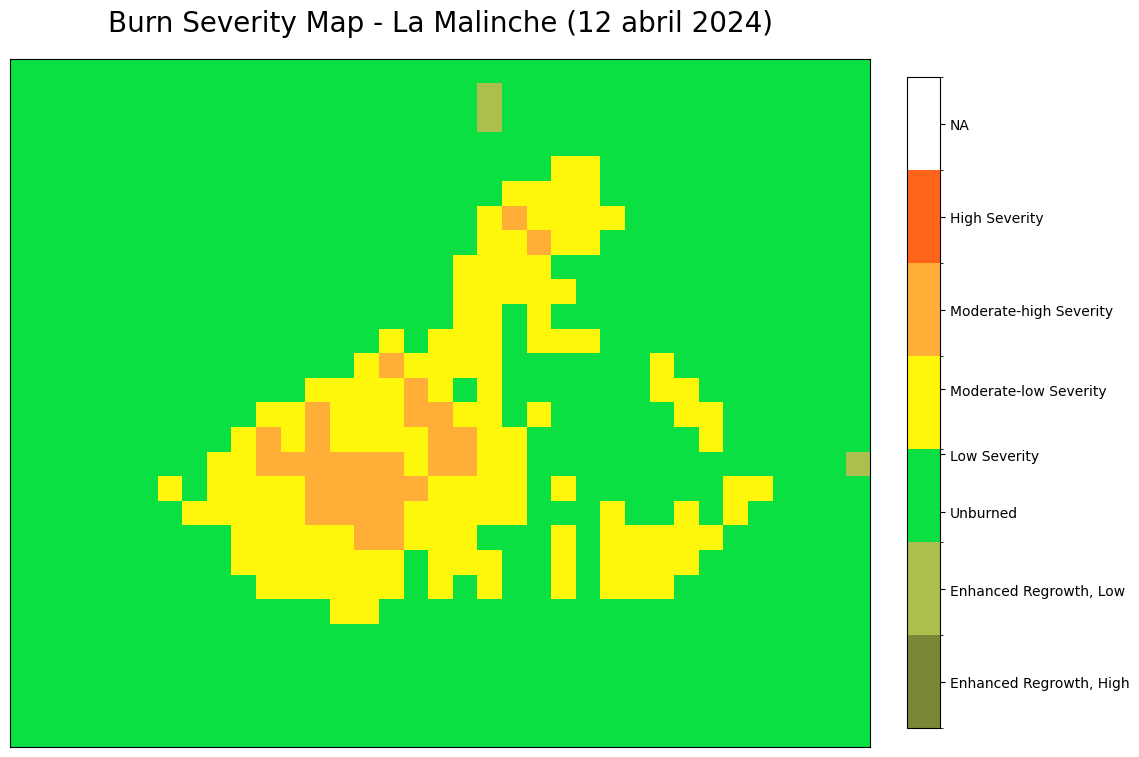

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2025_2



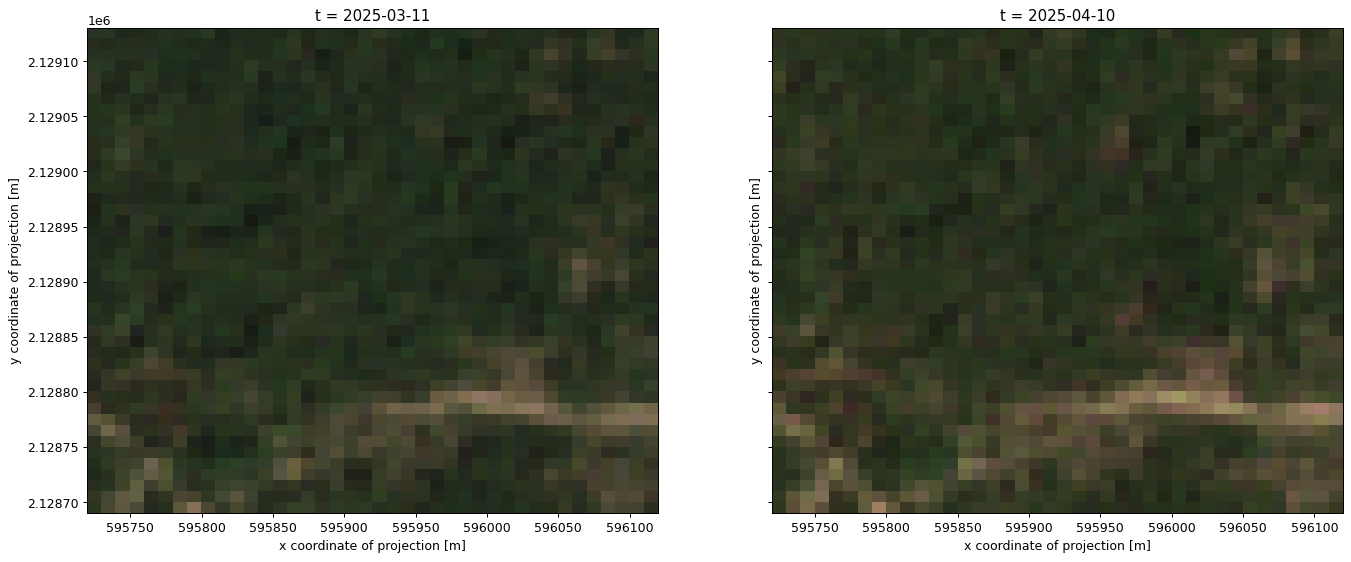

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2025-03-10", "2025-04-15"),
    spatial_extent={
        "west": -98.089111,
        "south": 19.249575,
        "east": -98.085447,
        "north": 19.253469,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

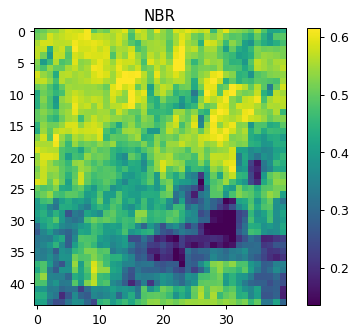

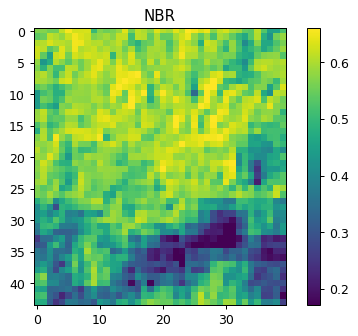

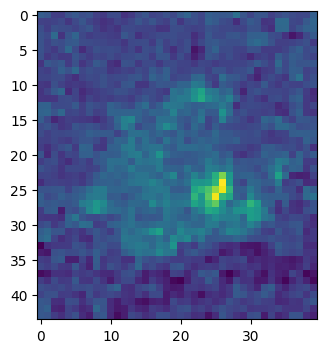

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2025-04-09", "2025-04-11"],
    bbox={
"west": -98.089111,
        "south": 19.249575,
        "east": -98.085447,
        "north": 19.253469,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2025-03-10", "2025-03-12"],
    bbox={
        "west": -98.089111,
        "south": 19.249575,
        "east": -98.085447,
        "north": 19.253469,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2025_2.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

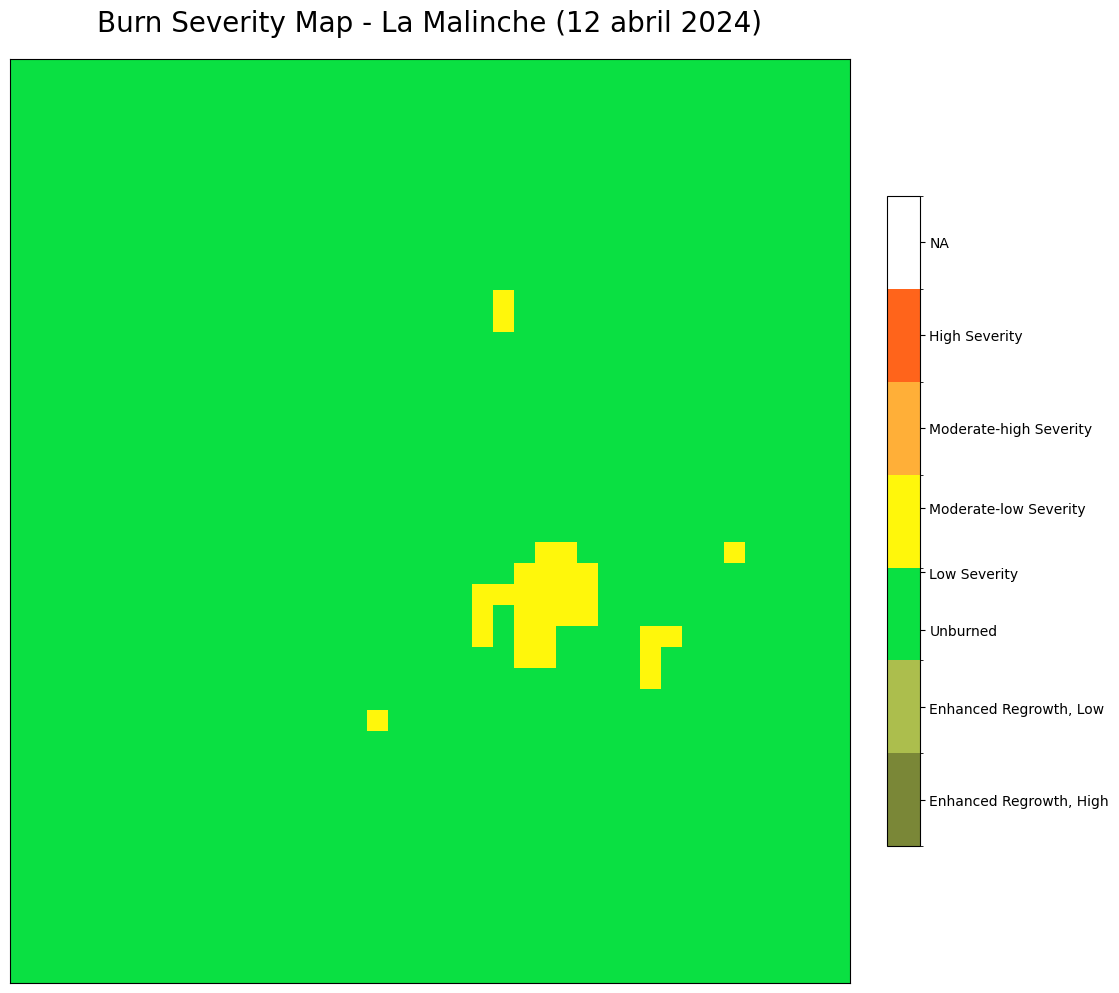

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2025_3



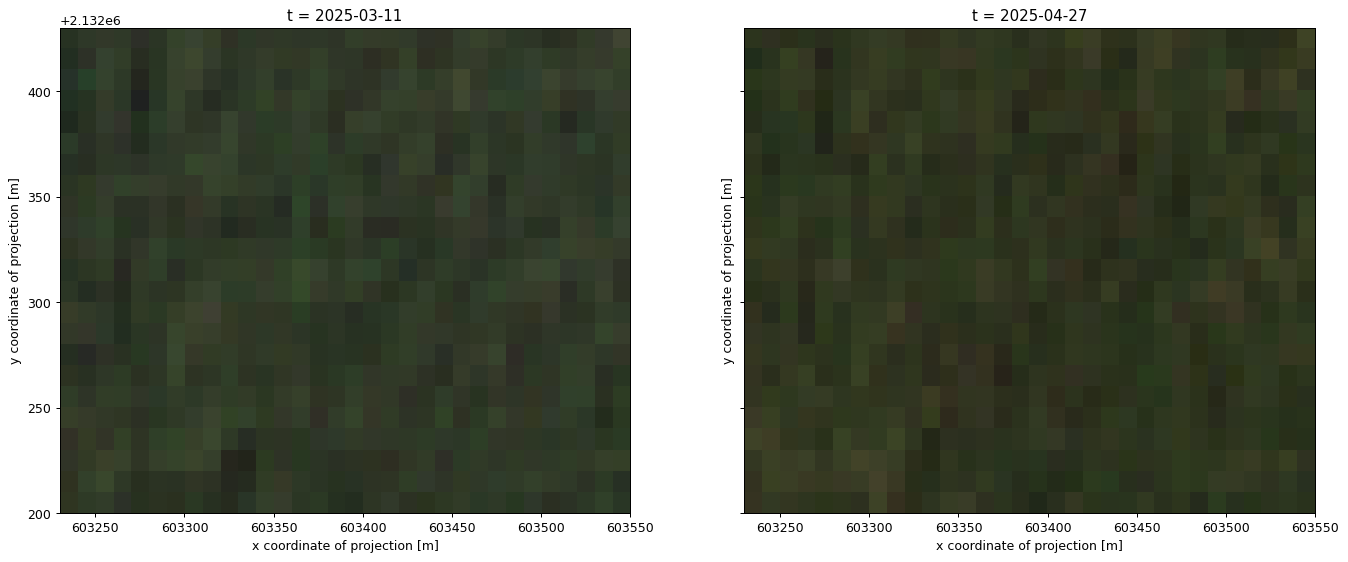

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2025-03-09", "2025-04-30"),
    spatial_extent={
        "west": -98.017476,
        "south": 19.280890,
        "east": -98.014613,
        "north": 19.282920,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

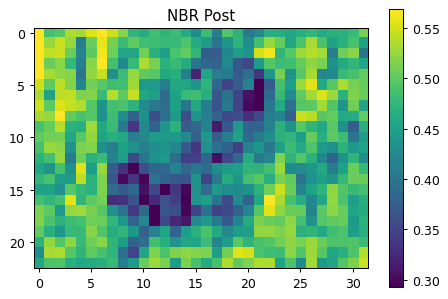

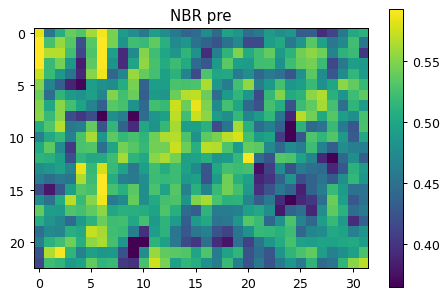

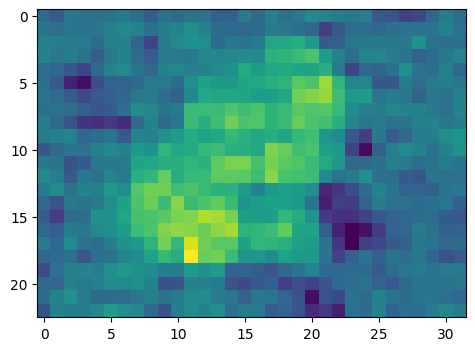

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2025-04-26", "2025-04-28"],
    bbox={
"west": -98.017476,
        "south": 19.280890,
        "east": -98.014613,
        "north": 19.282920,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR Post")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2025-03-10", "2025-03-12"],
    bbox={
        "west": -98.017476,
        "south": 19.280890,
        "east": -98.014613,
        "north": 19.282920,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR pre")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2025_3.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

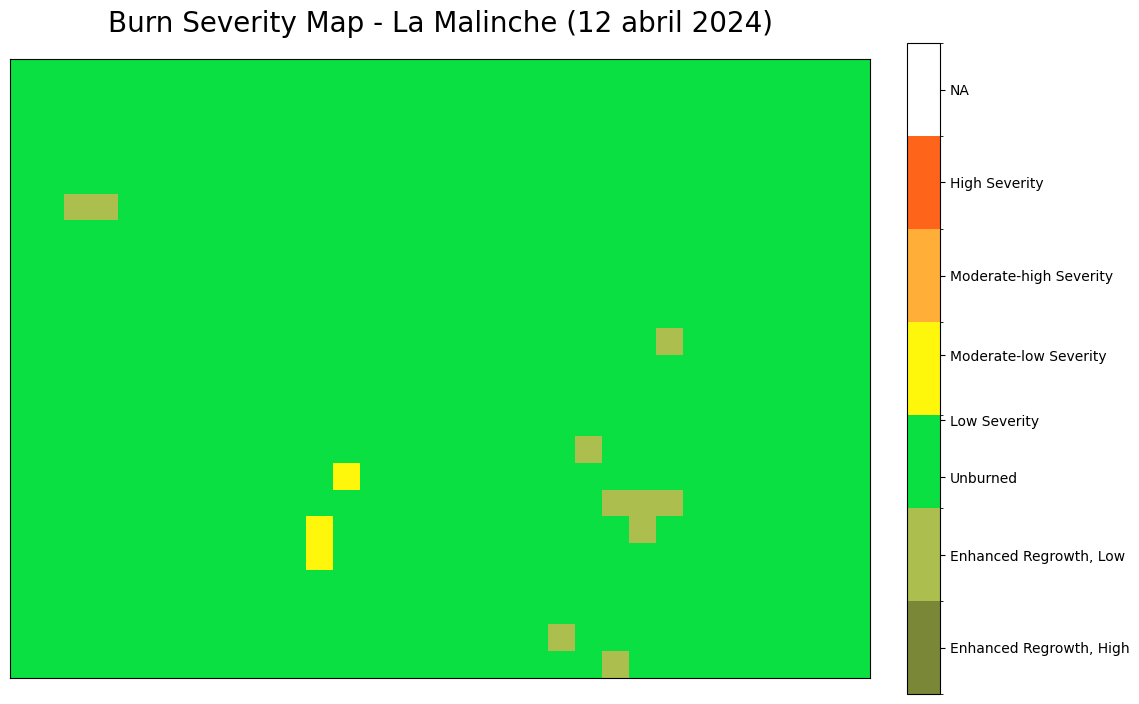

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta-
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2022_1



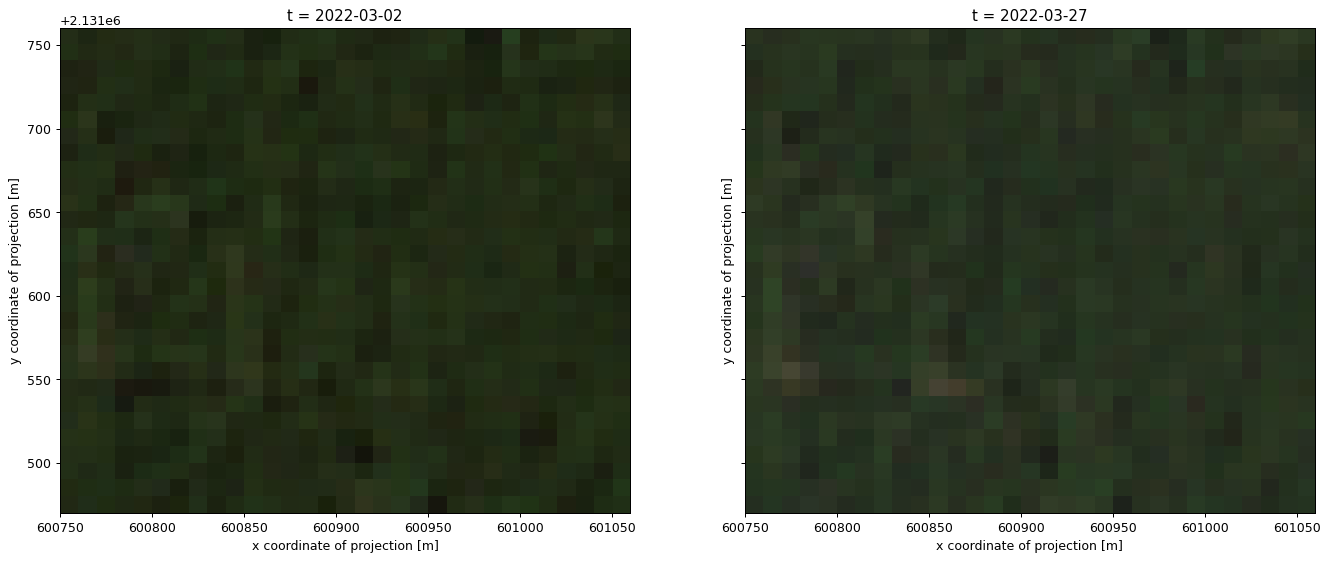

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2022-03-01", "2022-03-30"),
    spatial_extent={
        "west": -98.041162,
        "south": 19.274432,
        "east": -98.038348,
        "north": 19.276948,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

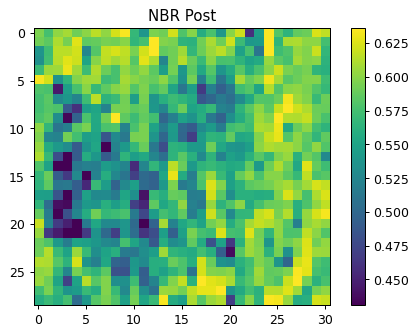

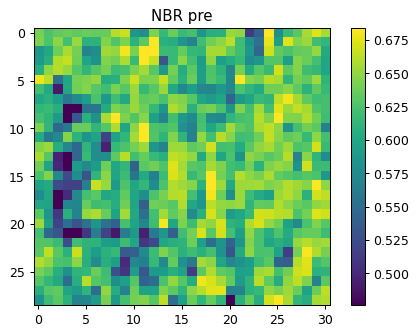

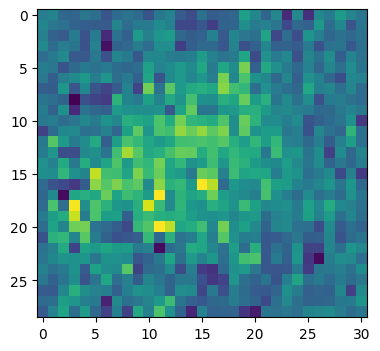

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2022-03-26", "2022-03-28"],
    bbox={
"west": -98.041162,
        "south": 19.274432,
        "east": -98.038348,
        "north": 19.276948,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR Post")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2022-03-01", "2022-03-03"],
    bbox={
        "west": -98.041162,
        "south": 19.274432,
        "east": -98.038348,
        "north": 19.276948,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR pre")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2022_1.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

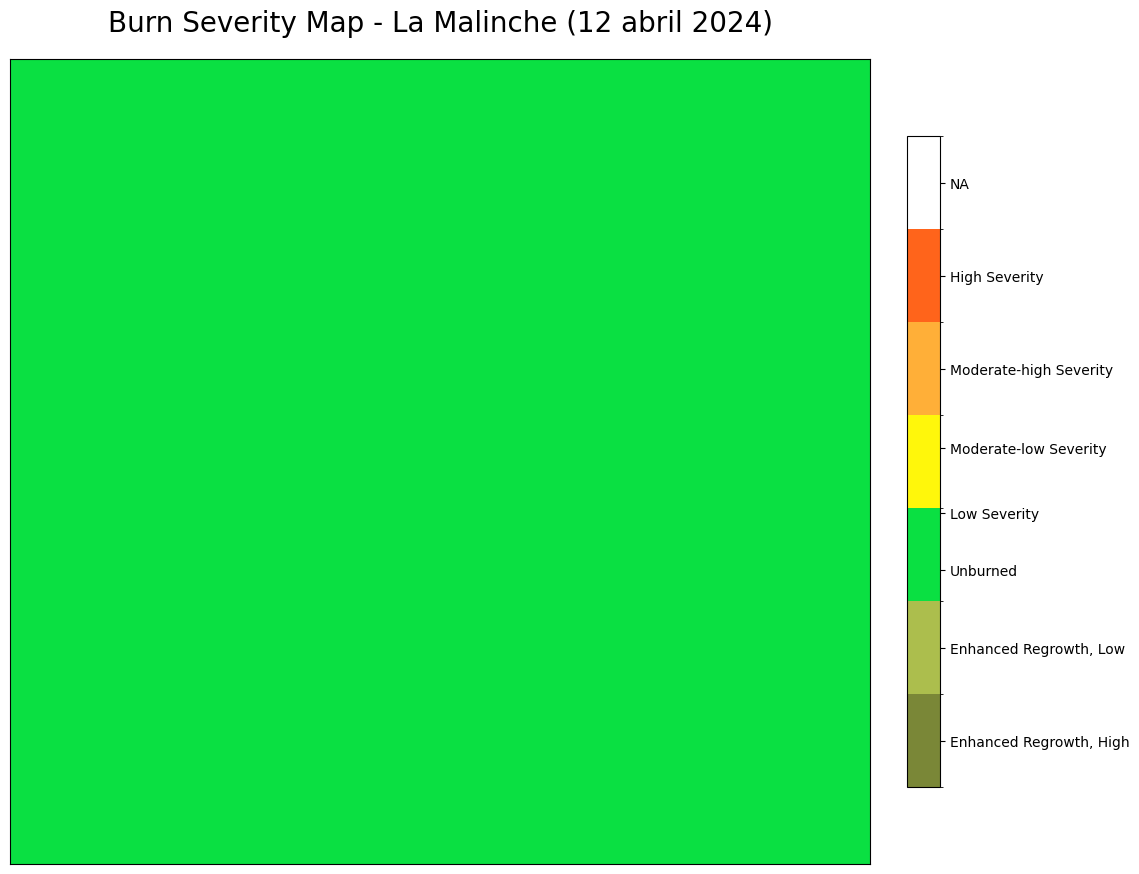

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2022_2



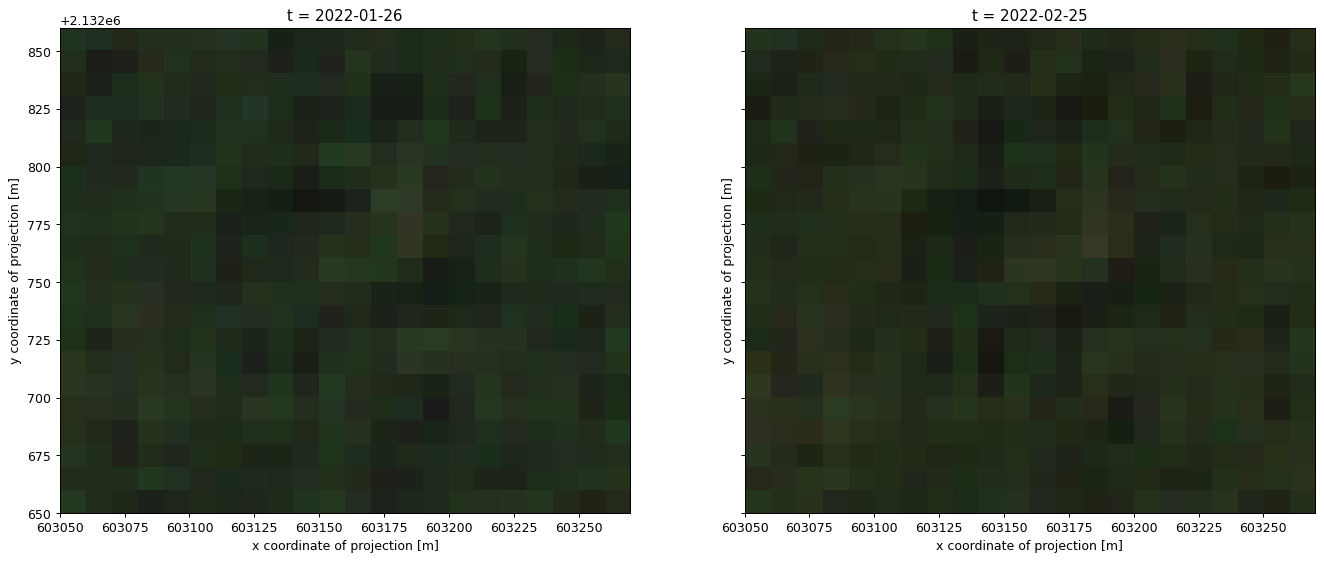

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2022-01-15", "2022-02-28"),
    spatial_extent={
        "west": -98.019215,
        "south": 19.285000,
        "east": -98.017233,
        "north": 19.286762,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

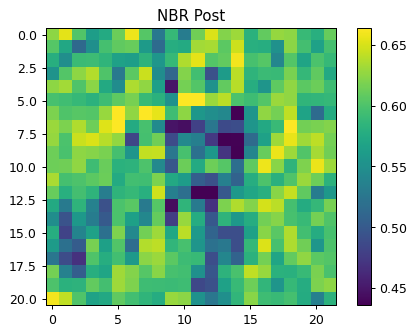

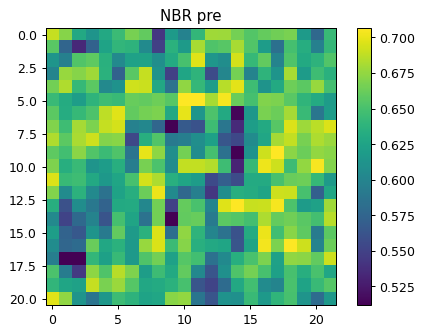

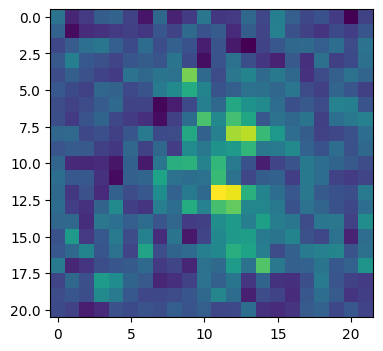

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2022-02-24", "2022-02-26"],
    bbox={
"west": -98.019215,
        "south": 19.285000,
        "east": -98.017233,
        "north": 19.286762,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR Post")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2022-01-25", "2022-01-27"],
    bbox={
        "west": -98.019215,
        "south": 19.285000,
        "east": -98.017233,
        "north": 19.286762,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR pre")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2022_2.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

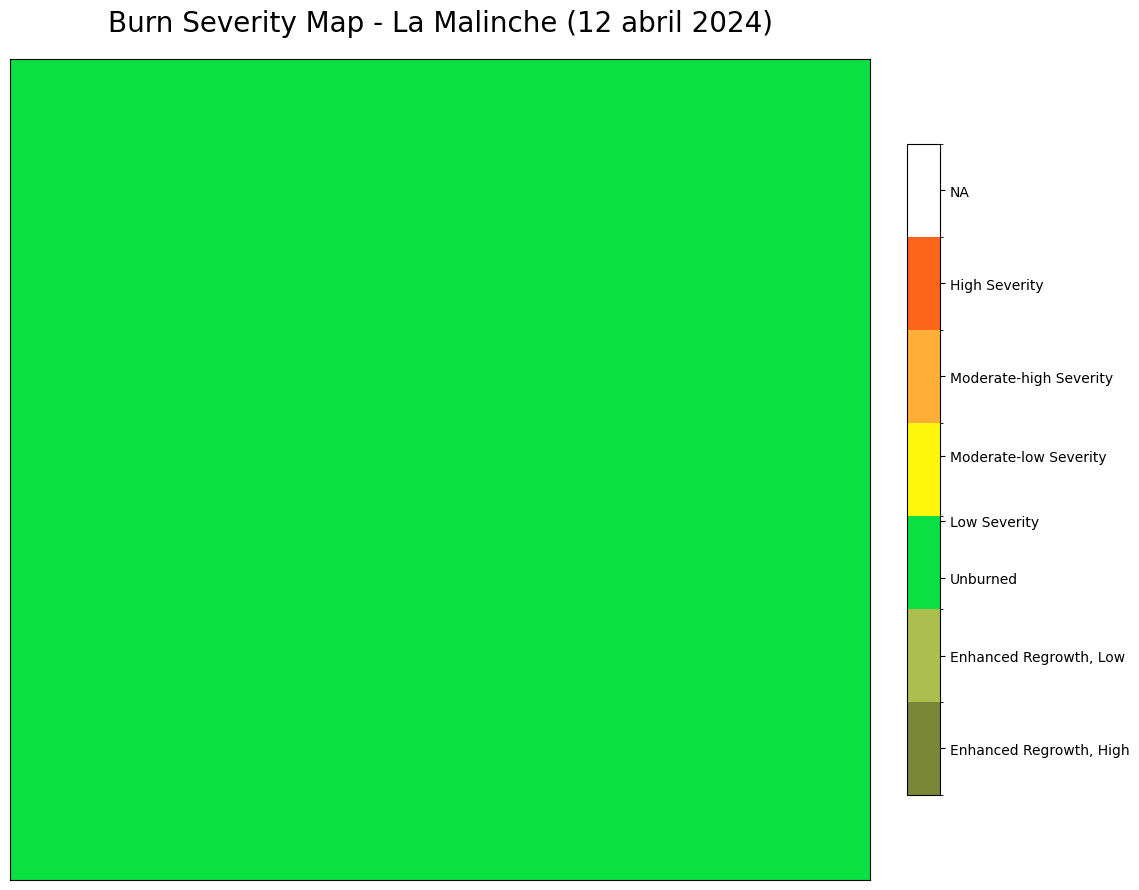

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()

#2022_3



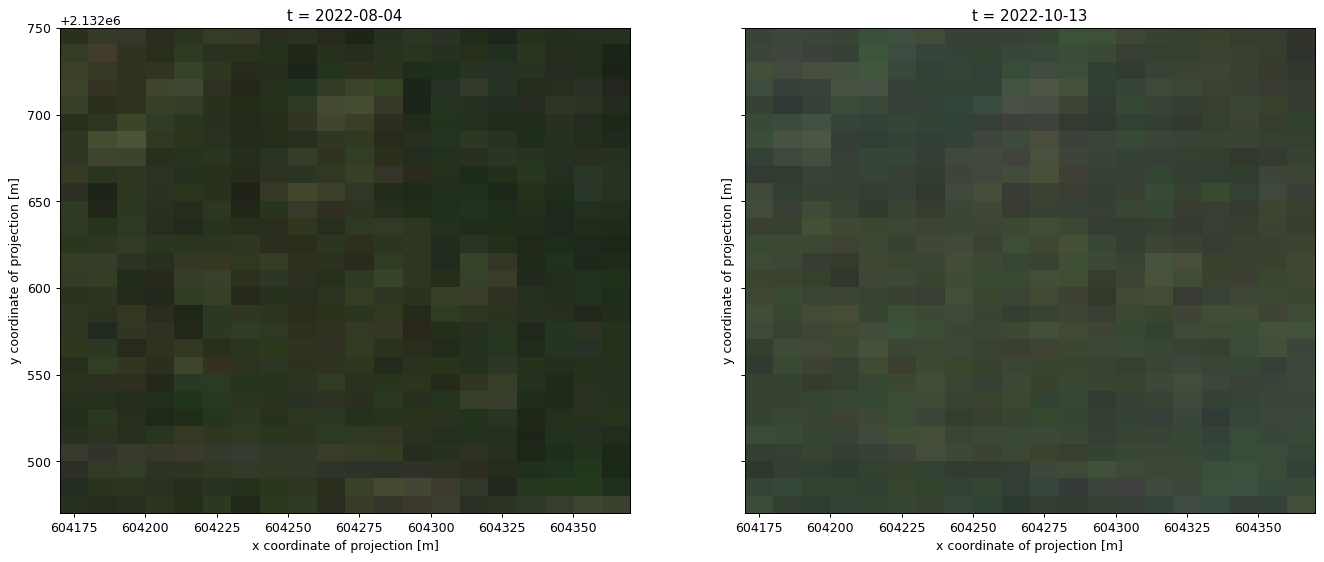

In [ ]:
s2_cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=("2022-08-01", "2022-10-15"),
    spatial_extent={
        "west": -98.008532,
        "south": 19.283302,
        "east": -98.006733,
        "north": 19.285738,
        "crs": "EPSG:4326",
    },
    bands=["B04", "B03", "B02", "SCL"],
    max_cloud_cover=10,
)
s2_cube.download("SanCristobal.nc")
ds = xarray.load_dataset("SanCristobal.nc")
# Convert xarray DataSet to a (bands, t, x, y) DataArray
data = ds[["B04", "B03", "B02"]].to_array(dim="bands")

fig, axes = plt.subplots(ncols=2, figsize=(18, 7), dpi=90, sharey=True)
data[{"t": 0}].plot.imshow(vmin=0, vmax=2000, ax=axes[0])
data[{"t": -1}].plot.imshow(vmin=0, vmax=2000, ax=axes[1]);

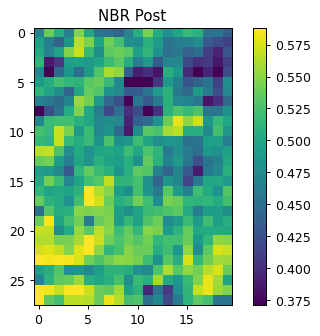

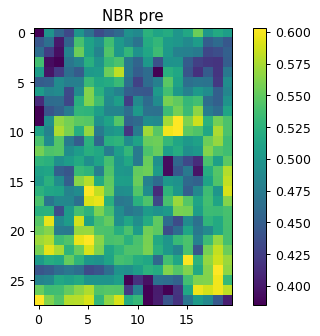

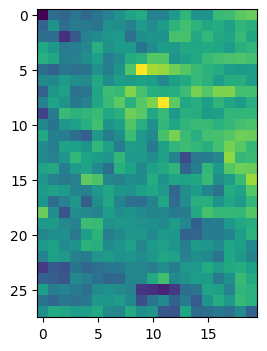

<Axes: >

In [ ]:
temporal_extent_param = Parameter(
    name="date_range",
    description="The date range to load.",
    schema={"type": "array", "subtype": "temporal-interval"},
)

spatial_extent_param = Parameter(
    name="bbox",
    description="The bounding box to load.",
    schema={"type": "object", "subtype": "geojson"},
)

band = ["B08", "B12"]
cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=temporal_extent_param,
    spatial_extent=spatial_extent_param,
    bands=band,
    max_cloud_cover=80,
)

nir = cube.band("B08")
swir = cube.band("B12")


nbr = (nir - swir) / (swir + nir)
nbr

nbr = nbr.max_time()

connection.save_user_defined_process(
    user_defined_process_id="NBR",
    process_graph=nbr,
    parameters=[temporal_extent_param, spatial_extent_param],
)

postbr2016 = connection.datacube_from_process(
    process_id="NBR",
    date_range=["2022-10-12", "2022-10-14"],
    bbox={
"west": -98.008532,
        "south": 19.283302,
        "east": -98.006733,
        "north": 19.285738,}
)



postbr2016.download("postnbr2016.tiff")

data = rasterio.open("postnbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR Post")
plt.colorbar(img)


prenbr2016 = connection.datacube_from_process(
    process_id="NBR",
date_range=["2022-08-03", "2022-08-05"],
    bbox={
        "west": -98.008532,
        "south": 19.283302,
        "east": -98.006733,
        "north": 19.285738,}
)
prenbr2016.download("prenbr2016.tiff")
data = rasterio.open("prenbr2016.tiff").read()

fig, ax = plt.subplots(figsize=(6, 4), dpi=90)
img = ax.imshow(data[0], vmin=np.percentile(data, 1), vmax=np.percentile(data, 99))
ax.set_title("NBR pre")
plt.colorbar(img)


pre_nbr = rasterio.open("prenbr2016.tiff")
post_nbr = rasterio.open("postnbr2016.tiff")

# Lee  las imágenes como array
pre = pre_nbr.read()
post = post_nbr.read()

dnbr = pre.astype(rasterio.float32)-post.astype(rasterio.float32)

meta = pre_nbr.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/2022_3.tif'

with rasterio.open(dnbr_path, 'w', **meta) as dest:
    dest.write(dnbr.astype(rasterio.float32))

img = rasterio.open(dnbr_path)
img_r = img.read()
image = np.asarray(img_r)

from rasterio.plot import show
fig = plt.figure(figsize=(6,4))
show(image)

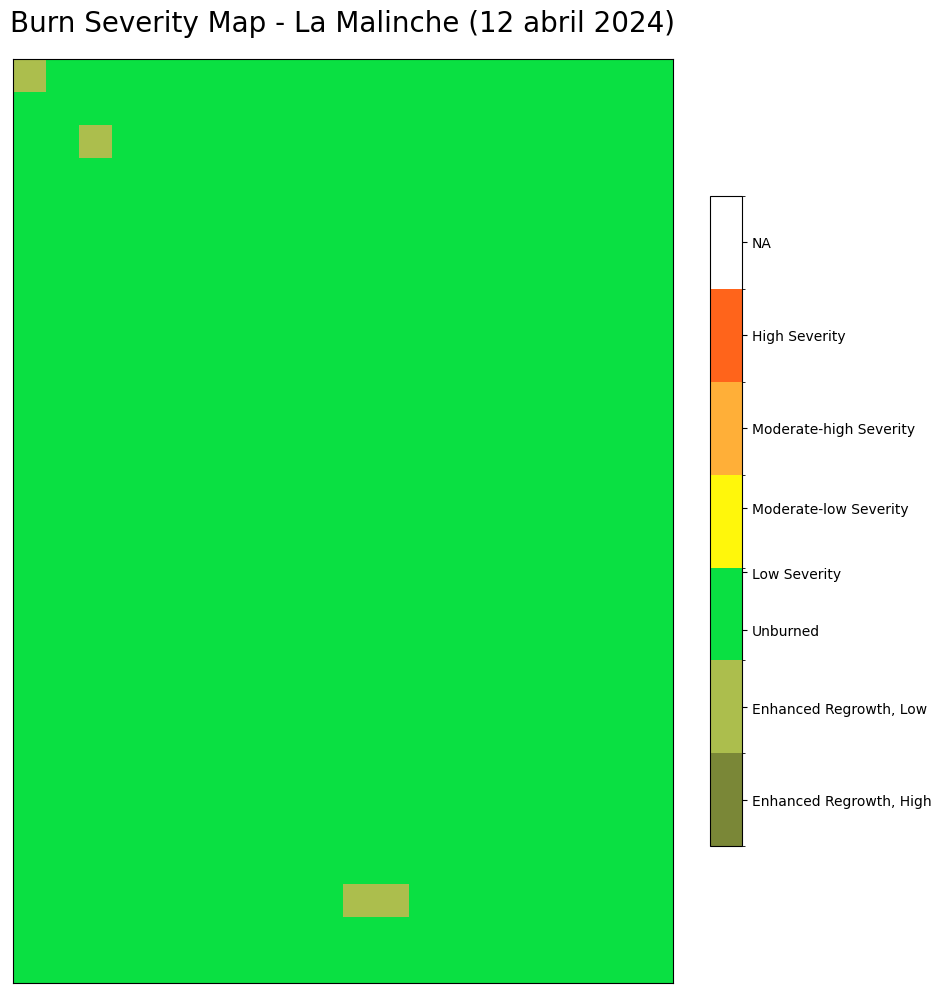

In [ ]:
dnbr_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/'
scl_image = rasterio.open(dnbr_path + "dnbr.tif")

scl = scl_image.read()
scl = np.array(scl)
scl

#Quitar el agua (6)
water = np.where(scl != 6, np.nan, scl)
water

meta = scl_image.meta
meta.update(driver='GTiff')
meta.update(dtype=rasterio.float32)

water_path = '/content/drive/MyDrive/1_UNAM/1_semestre/Montaña/proyecto_persona/water.tif'

with rasterio.open(water_path, 'w', **meta) as dest:
    dest.write(water.astype(rasterio.float32))

img = rasterio.open(dnbr_path + "dnbr.tif")
img_r = img.read(1)
#Se multiplica la matriz *1000 para reescalar y clasificar dentro de las clases
image = np.asarray(img_r)*1000

water_img = rasterio.open(water_path)
water_r = water_img.read(1)
water = np.asarray(water_r)

from matplotlib.colors import BoundaryNorm, ListedColormap
#Colores de las clases
cmap = ListedColormap([[122/255., 135/255., 55/255.],
                          [172/255., 190/255., 77/255.],
                          [10/255., 224/255., 66/255.],
                          [255/255., 247/255., 11/255.],
                          [255/255., 175/255., 56/255.],
                          [255/255., 100/255., 27/255.],
                          [164/255., 31/255., 214/255.],
                          [255/255., 255/255., 255/255.]])

import matplotlib.pyplot as plt
import matplotlib.colors
bounds = [-1000, -250, -101, 200, 439, 659, 1300, 2000]
norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

# Define the figure
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'xticks': [], 'yticks': []})

# Use `.imshow()` to plot the dNBR image with the custom colormap and norm
cax = ax.imshow(image, cmap=cmap, norm = norm)

# Add the water mask image to the figure using `.imshow()`
ax.imshow(water)

# Add a figure title
plt.title('Burn Severity Map - La Malinche (12 abril 2024)', fontsize=20, pad=20.0)

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.035, pad=0.04, ticks=[-625, -176, -1, 184, 354, 549, 980, 1650])

# Set the tick labels to reflect the burn severity classes
cbar.ax.set_yticklabels(['Enhanced Regrowth, High',
         'Enhanced Regrowth, Low',
         'Unburned',
         'Low Severity',
         'Moderate-low Severity',
         'Moderate-high Severity',
         'High Severity',
         'NA'])

# Show the plot
plt.show()